# Achievements and player reception

Run all cells. The first code cell loads the preparation notebook into this kernel, so this notebook can start from a fresh session. Put `games.csv` beside the notebooks first.


In [1]:
%%capture
%run ./01_data_loading.ipynb


## 1. Achievement counts — define groups before comparing outcomes

Using the refined Indie population released January 1, 2019 to December 25, 2025, with at least 100 recorded reviews and the existing product/title/price eligibility rules. `Achievements` is the recorded number offered, not the number players unlocked or a measure of achievement quality.

First inspect the counts and define practical, non-overlapping intervals: 0, 1–9, 10–24, 25–49, 50–99, and 100+. Zero means zero recorded achievements; absence versus collection failure cannot be independently verified from this field.

Do not select a 'best' count from group sizes. Subsequent analysis will compare reception and recorded review activity by supported play mode, considering genre and other differences. Such associations will not show that adding achievements causes success.

Use five nonzero intervals. Preserve zero in the data and summary table, but omit it from the distribution chart. Unequal interval widths mean bar counts describe these chosen categories, not probability density.

In [2]:
achievement_df = indie_focus_reviewed_df.copy()

# Validate before grouping: counts must be present, nonnegative integers.
achievement_count_checks = pd.Series({
    "Missing achievement counts": int(achievement_df["Achievements"].isna().sum()),
    "Negative achievement counts": int(achievement_df["Achievements"].lt(0).sum()),
    "Noninteger achievement counts": int(
        achievement_df["Achievements"].dropna().mod(1).ne(0).sum()
    ),
})
assert achievement_count_checks.eq(0).all(), achievement_count_checks

achievement_df["Achievements"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).round(2)

count    8467.00
mean       30.67
std       101.22
min         0.00
25%         6.00
50%        20.00
75%        38.00
90%        63.00
95%        89.00
99%       160.34
max      5394.00
Name: Achievements, dtype: float64

In [3]:
achievement_labels = ["0", "1–9", "10–24", "25–49", "50–99", "100+"]

achievement_df["achievement_group"] = pd.cut(
    achievement_df["Achievements"],
    bins=[-np.inf, 0, 9, 24, 49, 99, np.inf],
    labels=achievement_labels,
    right=True,
)

achievement_group_sizes = achievement_df.groupby(
    "achievement_group", observed=False
).agg(
    entries=("AppID", "size"),
    minimum_recorded=("Achievements", "min"),
    median_recorded=("Achievements", "median"),
    maximum_recorded=("Achievements", "max"),
)
achievement_group_sizes["pct_of_scope"] = (
    achievement_group_sizes["entries"] / len(achievement_df) * 100
)

achievement_group_sizes.round(1)

,entries,minimum_recorded,median_recorded,maximum_recorded,pct_of_scope
achievement_group,,,,,
0,1718,0,0.0,0,20.3
1–9,752,1,6.0,9,8.9
10–24,2336,10,16.0,24,27.6
25–49,2319,25,34.0,49,27.4
50–99,1013,50,63.0,99,12.0
100+,329,100,115.0,5394,3.9


### Distribution among entries with at least one recorded achievement

Show the five nonzero count ranges in numeric order. Zero-achievement entries are hidden only in this chart; they remain available for later comparisons. This chart describes how common the count ranges are, not which count produces better reception.


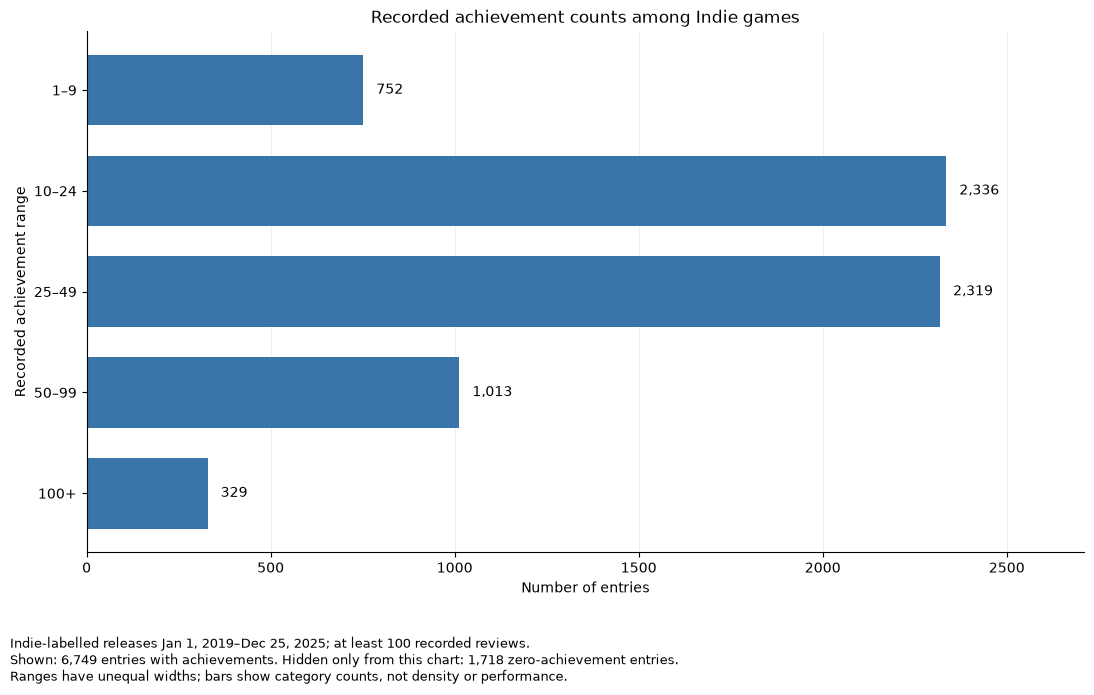

In [4]:
import matplotlib.pyplot as plt

achievement_plot_data = achievement_group_sizes.loc[
    achievement_labels[1:], "entries"
]
zero_achievement_entries = int(achievement_group_sizes.loc["0", "entries"])
nonzero_achievement_entries = int(achievement_plot_data.sum())

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(
    achievement_plot_data.index.astype(str),
    achievement_plot_data.to_numpy(),
    color="#3975a9", height=0.7,
)
ax.invert_yaxis()
ax.set_xlim(0, achievement_plot_data.max() * 1.16)

for position, count in enumerate(achievement_plot_data):
    ax.text(count + achievement_plot_data.max() * 0.015, position,
            f"{count:,}", va="center", fontsize=10)

ax.set(
    title="Recorded achievement counts among Indie games",
    xlabel="Number of entries",
    ylabel="Recorded achievement range",
)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
for edge in ["top", "right"]:
    ax.spines[edge].set_visible(False)

fig.text(
    0.01, 0.02,
    f"Indie-labelled releases Jan 1, 2019–Dec 25, 2025; at least 100 recorded reviews.\n"
    f"Shown: {nonzero_achievement_entries:,} entries with achievements. "
    f"Hidden only from this chart: {zero_achievement_entries:,} zero-achievement entries.\n"
    "Ranges have unequal widths; bars show category counts, not density or performance.",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()


### Extreme counts to revisit during sensitivity checks

The 100+ group is deliberately broad: the current sample includes 17 entries with at least 500 recorded achievements, and a maximum of 5,394. Preserve these observations rather than assuming they are errors. 

### Achievement groups: single-player versus multiplayer/co-op

Using the same 8,467 refined Indie entries with at least 100 recorded reviews. Join the earlier supported-mode classification by AppID, then combine co-op-capable and other multiplayer entries into one Multiplayer/co-op group. Games that also support single-player remain in the multiplayer/co-op group. Preserve the original classification for earlier reference analyses.

Recompute medians from individual entries in the combined group; do not average the previous group medians. Keep unknown modes separate. Each entry contributes once to a single achievement/mode combination.

Compare entry counts, median entry-level positive-review share, and median review volume. Keep zero achievements in the table but omit them from the heatmap. Show all observed nonzero combinations with counts; * flags n < 30. Genre, price, release period, updates, and exposure remain possible explanations for differences. These observational comparisons cannot identify a causal optimal achievement count.

In [5]:
achievement_mode_df = achievement_df.merge(
    mode_df[["AppID", "play_mode"]],
    on="AppID", how="left", validate="one_to_one",
)
assert achievement_mode_df["play_mode"].notna().all()

# Co-op is part of multiplayer; recompute medians from individual entries.
achievement_mode_order = [
    "Single-player only (recorded)", "Multiplayer/co-op",
]
achievement_mode_df["combined_play_mode"] = (
    achievement_mode_df["play_mode"].astype(str).replace({
        "Multiplayer without recorded co-op": "Multiplayer/co-op",
        "Co-op-capable": "Multiplayer/co-op",
    })
)

achievement_mode_summary_all = achievement_mode_df.groupby(
    ["achievement_group", "combined_play_mode"], observed=True
).agg(
    entries=("AppID", "size"),
    median_positive_pct=("positive_share", lambda values: values.median() * 100),
    median_total_reviews=("total_reviews", "median"),
)

achievement_mode_unknown = achievement_mode_df.loc[
    achievement_mode_df["combined_play_mode"].eq("Unknown/unclassified")
].copy()
print("Unknown/unclassified entries outside the two-group comparison:",
      len(achievement_mode_unknown))

achievement_mode_summary = achievement_mode_summary_all.loc[
    achievement_mode_summary_all.index.get_level_values("combined_play_mode").isin(achievement_mode_order)
].copy()

achievement_mode_table = (
    achievement_mode_summary[["entries", "median_positive_pct", "median_total_reviews"]]
    .unstack("combined_play_mode")
    .swaplevel(0, 1, axis=1)
    .reindex(columns=achievement_mode_order, level=0)
    .reindex(achievement_labels)
)
achievement_mode_table.round(1)

Unknown/unclassified entries outside the two-group comparison: 80


combined_play_mode Single-player only (recorded)                      \
                                         entries median_positive_pct   
achievement_group                                                      
0                                           1253                85.7   
1–9                                          638                87.6   
10–24                                       1872                87.7   
25–49                                       1736                86.4   
50–99                                        742                86.1   
100+                                         250                89.7   

combined_play_mode                      Multiplayer/co-op                      \
                   median_total_reviews           entries median_positive_pct   
achievement_group                                                               
0                                 256.0               446                77.9   
1–9                               226.0               107                78.0   
10–24                             299.0               439                83.1   
25–49                             437.5               564                84.2   
50–99                             536.0               265                85.5   
100+                              903.5                75                85.6   

combined_play_mode                       
                   median_total_reviews  
achievement_group                        
0                                 392.0  
1–9                               279.0  
10–24                             458.0  
25–49                             574.5  
50–99                            1155.0  
100+                             1657.0

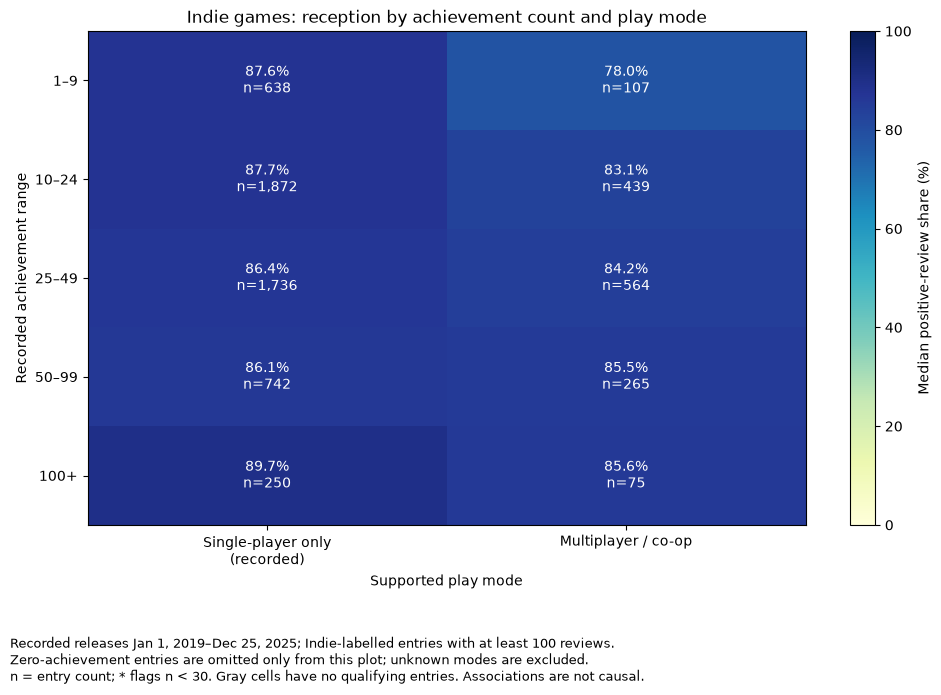

In [6]:
import matplotlib.pyplot as plt

achievement_mode_reception = (
    achievement_mode_summary["median_positive_pct"].unstack("combined_play_mode")
    .reindex(index=achievement_labels[1:], columns=achievement_mode_order)
)
achievement_mode_counts = (
    achievement_mode_summary["entries"].unstack("combined_play_mode")
    .reindex(index=achievement_labels[1:], columns=achievement_mode_order)
)

values = np.ma.masked_invalid(achievement_mode_reception.to_numpy(dtype=float))
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#eeeeee")
fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(values, cmap=cmap, vmin=0, vmax=100, aspect="auto")
fig.colorbar(image, ax=ax, label="Median positive-review share (%)")
ax.set_xticks(range(2), [
    "Single-player only\n(recorded)", "Multiplayer / co-op",
])
ax.set_yticks(range(len(achievement_mode_reception)), achievement_mode_reception.index.astype(str))

for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        if not np.ma.is_masked(values[row, col]):
            value = float(values[row, col])
            count = int(achievement_mode_counts.iloc[row, col])
            flag = "*" if count < 30 else ""
            ax.text(col, row, f"{value:.1f}%\nn={count:,}{flag}",
                    ha="center", va="center", fontsize=10,
                    color="white" if value >= 65 else "black")

ax.set(title="Indie games: reception by achievement count and play mode",
       xlabel="Supported play mode", ylabel="Recorded achievement range")
fig.text(
    0.01, 0.02,
    "Recorded releases Jan 1, 2019–Dec 25, 2025; Indie-labelled entries with at least 100 reviews.\n"
    "Zero-achievement entries are omitted only from this plot; unknown modes are excluded.\n"
    "n = entry count; * flags n < 30. Gray cells have no qualifying entries. Associations are not causal.",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.13, 1, 1])
plt.show()

## 3. Single-player achievement distributions by reception tier

Restrict the current Indie 2019–2025, 100+ recorded review population to Single-player only (recorded). Define mutually exclusive reception tiers using unrounded positive-review shares: above 85%; 65% through 85% inclusive; below 65%.

Compare the distribution of achievement groups **within each reception tier**, rather than raw counts between tiers. Keep zero achievements in the data and tier-size audit, but omit them from the chart as previously requested. Recalculate displayed percentages among nonzero-achievement entries in each tier so each plotted distribution totals 100%. These percentages describe achievement mixes conditional on reception; they are not the probability of high reception given an achievement count. Neither this chart nor the most common range establishes an optimal count or a causal effect.

Refine the dense 10–49 region into four equal-width ranges: 10–19, 20–29, 30–39, and 40–49. Also split 50–99 into 50–59, 60–69, and 70–99; keep 1–9 and 100+ unchanged. This local refinement affects this distribution comparison only; earlier achievement tables and heatmaps retain their original intervals. Inspect similarities as well as differences; changing ranges on the same data is exploratory, not independent validation.

In [7]:
single_achievement_df = achievement_mode_df.loc[
    achievement_mode_df["combined_play_mode"].eq("Single-player only (recorded)")
].copy()

# Local ranges for this deeper distribution comparison only.
single_achievement_labels = [
    "0", "1–9", "10–19", "20–29", "30–39", "40–49", "50–59", "60–69", "70–99", "100+",
]
single_achievement_df["achievement_group"] = pd.cut(
    single_achievement_df["Achievements"],
    bins=[-np.inf, 0, 9, 19, 29, 39, 49, 59, 69, 99, np.inf],
    labels=single_achievement_labels, right=True,
)

reception_tier_order = ["Above 85%", "65–85%", "Below 65%"]
single_achievement_df["reception_tier"] = np.select(
    [
        single_achievement_df["positive_share"].gt(0.85),
        single_achievement_df["positive_share"].between(0.65, 0.85),
    ],
    reception_tier_order[:2],
    default=reception_tier_order[2],
)
single_achievement_df["reception_tier"] = pd.Categorical(
    single_achievement_df["reception_tier"],
    categories=reception_tier_order, ordered=True,
)

single_tier_achievement_counts = pd.crosstab(
    single_achievement_df["achievement_group"],
    single_achievement_df["reception_tier"], dropna=False,
).reindex(index=single_achievement_labels, columns=reception_tier_order, fill_value=0)

single_tier_sizes = pd.DataFrame({
    "All entries in tier": single_tier_achievement_counts.sum(axis=0),
    "Zero achievements (hidden in plot)": single_tier_achievement_counts.loc["0"],
    "Nonzero achievements (shown)": single_tier_achievement_counts.loc[single_achievement_labels[1:]].sum(axis=0),
})
single_tier_sizes

,All entries in tier,Zero achievements (hidden in plot),Nonzero achievements (shown)
reception_tier,,,
Above 85%,3636,657,2979
65–85%,2331,445,1886
Below 65%,524,151,373


In [8]:
single_tier_plot_counts = single_tier_achievement_counts.loc[
    single_achievement_labels[1:]
].copy()
single_tier_plot_pct = single_tier_plot_counts.div(
    single_tier_plot_counts.sum(axis=0).replace(0, np.nan), axis=1
) * 100

single_tier_distribution_table = pd.concat({
    "Entries": single_tier_plot_counts,
    "Within-tier (%)": single_tier_plot_pct,
}, axis=1)
single_tier_distribution_table.round(1)

Entries                  Within-tier (%)                 
reception_tier    Above 85% 65–85% Below 65%       Above 85% 65–85% Below 65%
achievement_group                                                            
1–9                     371    222        45            12.5   11.8      12.1
10–19                   748    422        86            25.1   22.4      23.1
20–29                   613    396        89            20.6   21.0      23.9
30–39                   413    292        69            13.9   15.5      18.5
40–49                   274    178        28             9.2    9.4       7.5
50–59                   132    138        22             4.4    7.3       5.9
60–69                   105     64        13             3.5    3.4       3.5
70–99                   160     99         9             5.4    5.2       2.4
100+                    163     75        12             5.5    4.0       3.2

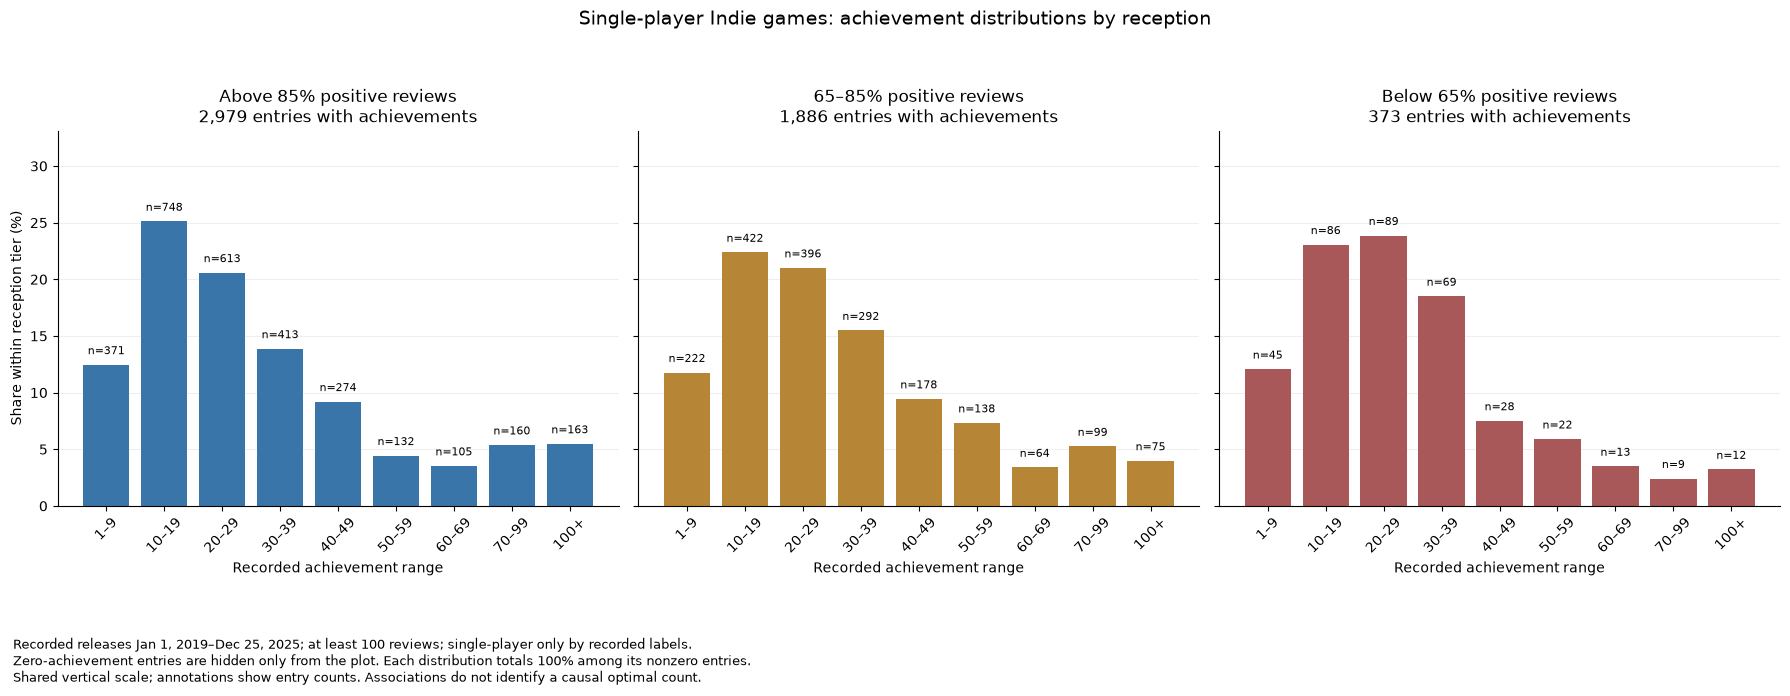

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
colors = ["#3975a9", "#b78536", "#a85858"]
common_upper = min(100, single_tier_plot_pct.max().max() * 1.2 + 3)

for ax, tier, color in zip(axes, reception_tier_order, colors):
    counts = single_tier_plot_counts[tier]
    percentages = single_tier_plot_pct[tier]
    ax.bar(single_achievement_labels[1:], percentages.to_numpy(), color=color)
    for position, (count, percentage) in enumerate(zip(counts, percentages)):
        if pd.notna(percentage):
            ax.text(position, percentage + 0.7, f"n={int(count):,}",
                    ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{tier} positive reviews\n{int(counts.sum()):,} entries with achievements")
    ax.set_xlabel("Recorded achievement range")
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(0, common_upper)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    for edge in ["top", "right"]:
        ax.spines[edge].set_visible(False)

axes[0].set_ylabel("Share within reception tier (%)")
fig.suptitle("Single-player Indie games: achievement distributions by reception", fontsize=14)
fig.text(
    0.01, 0.02,
    "Recorded releases Jan 1, 2019–Dec 25, 2025; at least 100 reviews; single-player only by recorded labels.\n"
    "Zero-achievement entries are hidden only from the plot. Each distribution totals 100% among its nonzero entries.\n"
    "Shared vertical scale; annotations show entry counts. Associations do not identify a causal optimal count.",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.15, 1, 0.94])
plt.show()

## 4. Multiplayer/co-op achievement distributions by reception tier

Restrict the current Indie 2019–2025, 100+ recorded review population to the combined Multiplayer/co-op group. Define mutually exclusive reception tiers using unrounded positive-review shares: above 85%; 65% through 85% inclusive; below 65%.

Compare the distribution of achievement groups **within each reception tier**, rather than raw counts between tiers. Keep zero achievements in the data and tier-size audit, but omit them from the chart as previously requested. Recalculate displayed percentages among nonzero-achievement entries in each tier so each plotted distribution totals 100%. These percentages describe achievement mixes conditional on reception; they are not the probability of high reception given an achievement count. Neither this chart nor the most common range establishes an optimal count or a causal effect.

Refine the dense 10–49 region into four equal-width ranges: 10–19, 20–29, 30–39, and 40–49. Also split 50–99 into 50–59, 60–69, and 70–99; keep 1–9 and 100+ unchanged. This local refinement affects this distribution comparison only; earlier achievement tables and heatmaps retain their original intervals. Co-op-capable and other multiplayer entries are pooled at the entry level; games that also support single-player remain in this combined group. Inspect similarities as well as differences; changing ranges on the same data is exploratory, not independent validation.

In [10]:
multiplayer_achievement_df = achievement_mode_df.loc[
    achievement_mode_df["combined_play_mode"].eq("Multiplayer/co-op")
].copy()

# Local ranges for this deeper distribution comparison only.
multiplayer_achievement_labels = [
    "0", "1–9", "10–19", "20–29", "30–39", "40–49", "50–59", "60–69", "70–99", "100+",
]
multiplayer_achievement_df["achievement_group"] = pd.cut(
    multiplayer_achievement_df["Achievements"],
    bins=[-np.inf, 0, 9, 19, 29, 39, 49, 59, 69, 99, np.inf],
    labels=multiplayer_achievement_labels, right=True,
)

reception_tier_order = ["Above 85%", "65–85%", "Below 65%"]
multiplayer_achievement_df["reception_tier"] = np.select(
    [
        multiplayer_achievement_df["positive_share"].gt(0.85),
        multiplayer_achievement_df["positive_share"].between(0.65, 0.85),
    ],
    reception_tier_order[:2],
    default=reception_tier_order[2],
)
multiplayer_achievement_df["reception_tier"] = pd.Categorical(
    multiplayer_achievement_df["reception_tier"],
    categories=reception_tier_order, ordered=True,
)

multiplayer_tier_achievement_counts = pd.crosstab(
    multiplayer_achievement_df["achievement_group"],
    multiplayer_achievement_df["reception_tier"], dropna=False,
).reindex(index=multiplayer_achievement_labels, columns=reception_tier_order, fill_value=0)

multiplayer_tier_sizes = pd.DataFrame({
    "All entries in tier": multiplayer_tier_achievement_counts.sum(axis=0),
    "Zero achievements (hidden in plot)": multiplayer_tier_achievement_counts.loc["0"],
    "Nonzero achievements (shown)": multiplayer_tier_achievement_counts.loc[multiplayer_achievement_labels[1:]].sum(axis=0),
})
multiplayer_tier_sizes

,All entries in tier,Zero achievements (hidden in plot),Nonzero achievements (shown)
reception_tier,,,
Above 85%,823,160,663
65–85%,819,188,631
Below 65%,254,98,156


In [11]:
multiplayer_tier_plot_counts = multiplayer_tier_achievement_counts.loc[
    multiplayer_achievement_labels[1:]
].copy()
multiplayer_tier_plot_pct = multiplayer_tier_plot_counts.div(
    multiplayer_tier_plot_counts.sum(axis=0).replace(0, np.nan), axis=1
) * 100

multiplayer_tier_distribution_table = pd.concat({
    "Entries": multiplayer_tier_plot_counts,
    "Within-tier (%)": multiplayer_tier_plot_pct,
}, axis=1)
multiplayer_tier_distribution_table.round(1)

Entries                  Within-tier (%)                 
reception_tier    Above 85% 65–85% Below 65%       Above 85% 65–85% Below 65%
achievement_group                                                            
1–9                      28     55        24             4.2    8.7      15.4
10–19                   125    127        38            18.9   20.1      24.4
20–29                   134    144        39            20.2   22.8      25.0
30–39                   113     99        27            17.0   15.7      17.3
40–49                    89     63         5            13.4   10.0       3.2
50–59                    52     39         6             7.8    6.2       3.8
60–69                    36     25         6             5.4    4.0       3.8
70–99                    47     45         9             7.1    7.1       5.8
100+                     39     34         2             5.9    5.4       1.3

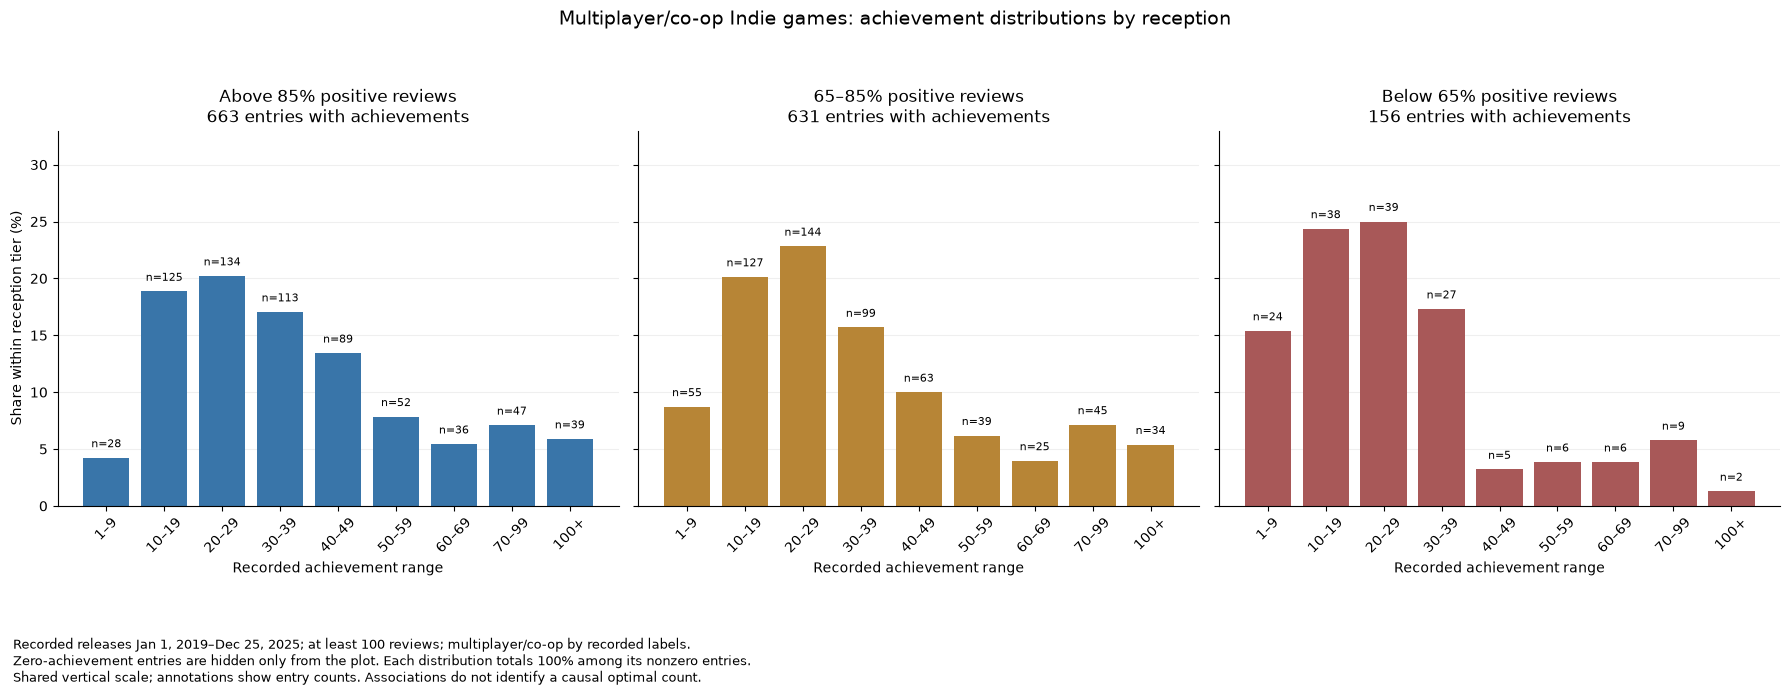

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
colors = ["#3975a9", "#b78536", "#a85858"]
common_upper = min(100, multiplayer_tier_plot_pct.max().max() * 1.2 + 3)

for ax, tier, color in zip(axes, reception_tier_order, colors):
    counts = multiplayer_tier_plot_counts[tier]
    percentages = multiplayer_tier_plot_pct[tier]
    ax.bar(multiplayer_achievement_labels[1:], percentages.to_numpy(), color=color)
    for position, (count, percentage) in enumerate(zip(counts, percentages)):
        if pd.notna(percentage):
            ax.text(position, percentage + 0.7, f"n={int(count):,}",
                    ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{tier} positive reviews\n{int(counts.sum()):,} entries with achievements")
    ax.set_xlabel("Recorded achievement range")
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(0, common_upper)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    for edge in ["top", "right"]:
        ax.spines[edge].set_visible(False)

axes[0].set_ylabel("Share within reception tier (%)")
fig.suptitle("Multiplayer/co-op Indie games: achievement distributions by reception", fontsize=14)
fig.text(
    0.01, 0.02,
    "Recorded releases Jan 1, 2019–Dec 25, 2025; at least 100 reviews; multiplayer/co-op by recorded labels.\n"
    "Zero-achievement entries are hidden only from the plot. Each distribution totals 100% among its nonzero entries.\n"
    "Shared vertical scale; annotations show entry counts. Associations do not identify a causal optimal count.",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.15, 1, 0.94])
plt.show()

## 5. Which gameplay genres have different achievement distributions?

Use the same Indie 2019–2025, 100+ review population. Keep single-player-only and combined multiplayer/co-op separate; omit Unknown/unclassified. As in the previous distribution charts, compare only entries with at least one recorded achievement. Zero-achievement records remain in the earlier audit tables.

Compare eight gameplay genres: Action, Adventure, Casual, RPG, Simulation, Strategy, Sports, and Racing. Each title may carry several genre labels, so genre profiles overlap; within any one profile, count each title once.

For each genre/mode profile, compare its normalized achievement-range distribution with entries **without that genre label in the same play mode**. The descriptive distribution gap is half the sum of absolute percentage differences across ranges (0 means identical, 100 means disjoint distributions). This is a ranking of distributional differences, not a significance test or causal effect. Plot only profiles with at least 50 entries and at least 50 comparison entries; the threshold is a practical display rule.

Use count medians, upper-tail shares, and sample sizes to interpret differences. A popular range is not an optimal achievement count. These initial genre distributions do not condition on reception tier, price, or release period; any promising pattern needs those follow-up comparisons before recommendations.

In [13]:
genre_achievement_source = achievement_mode_df.loc[
    achievement_mode_df["Achievements"].gt(0)
    & achievement_mode_df["combined_play_mode"].isin(achievement_mode_order)
].copy()
genre_achievement_labels = single_achievement_labels[1:]
genre_achievement_source["detailed_achievement_group"] = pd.cut(
    genre_achievement_source["Achievements"],
    bins=[0, 9, 19, 29, 39, 49, 59, 69, 99, np.inf],
    labels=genre_achievement_labels, right=True,
)
gameplay_achievement_genres = [
    "Action", "Adventure", "Casual", "RPG",
    "Simulation", "Strategy", "Sports", "Racing",
]
genre_achievement_sets = genre_achievement_source["Genres"].fillna("").str.split(",").apply(
    lambda labels: {label.strip() for label in labels}
)

genre_achievement_rows = []
genre_achievement_profiles = {}
for play_mode in achievement_mode_order:
    mode_mask = genre_achievement_source["combined_play_mode"].eq(play_mode)
    for genre in gameplay_achievement_genres:
        has_genre = genre_achievement_sets.apply(lambda labels: genre in labels)
        selected = genre_achievement_source.loc[mode_mask & has_genre]
        comparison = genre_achievement_source.loc[mode_mask & ~has_genre]
        if selected.empty or comparison.empty:
            continue

        selected_pct = selected["detailed_achievement_group"].value_counts(
            sort=False
        ).reindex(genre_achievement_labels, fill_value=0) / len(selected) * 100
        comparison_pct = comparison["detailed_achievement_group"].value_counts(
            sort=False
        ).reindex(genre_achievement_labels, fill_value=0) / len(comparison) * 100

        profile_key = (genre, play_mode)
        genre_achievement_profiles[profile_key] = pd.DataFrame({
            "Genre (%)": selected_pct,
            "Other entries in same mode (%)": comparison_pct,
        })
        genre_achievement_rows.append({
            "genre": genre,
            "play_mode": play_mode,
            "entries": len(selected),
            "comparison_entries": len(comparison),
            "median_achievements": selected["Achievements"].median(),
            "pct_10_to_29": selected["Achievements"].between(10, 29).mean() * 100,
            "pct_50_plus": selected["Achievements"].ge(50).mean() * 100,
            "pct_100_plus": selected["Achievements"].ge(100).mean() * 100,
            "distribution_gap_pp": (selected_pct - comparison_pct).abs().sum() / 2,
            "enough_for_display": len(selected) >= 50 and len(comparison) >= 50,
        })

genre_achievement_summary = pd.DataFrame(genre_achievement_rows).sort_values(
    "distribution_gap_pp", ascending=False
)
genre_achievement_summary.round(1)

,genre,play_mode,entries,comparison_entries,median_achievements,pct_10_to_29,pct_50_plus,pct_100_plus,distribution_gap_pp,enough_for_display
11,RPG,Multiplayer/co-op,351,1099,38.0,28.2,34.5,7.4,22.9,True
5,Strategy,Single-player only (recorded),1245,3993,35.0,33.1,31.1,7.2,22.1,True
3,RPG,Single-player only (recorded),1501,3737,33.0,36.0,29.9,7.5,20.8,True
15,Racing,Multiplayer/co-op,99,1351,27.0,52.5,15.2,3.0,18.4,True
10,Casual,Multiplayer/co-op,553,897,26.0,46.1,22.4,5.8,11.9,True
7,Racing,Single-player only (recorded),75,5163,29.0,38.7,18.7,0.0,11.6,True
14,Sports,Multiplayer/co-op,125,1325,26.0,48.8,16.8,4.0,10.4,True
13,Strategy,Multiplayer/co-op,370,1080,34.0,38.6,30.3,7.6,9.6,True
2,Casual,Single-player only (recorded),2010,3228,24.0,46.1,19.9,6.2,9.4,True
8,Action,Multiplayer/co-op,965,485,30.0,40.5,22.0,4.8,9.2,True


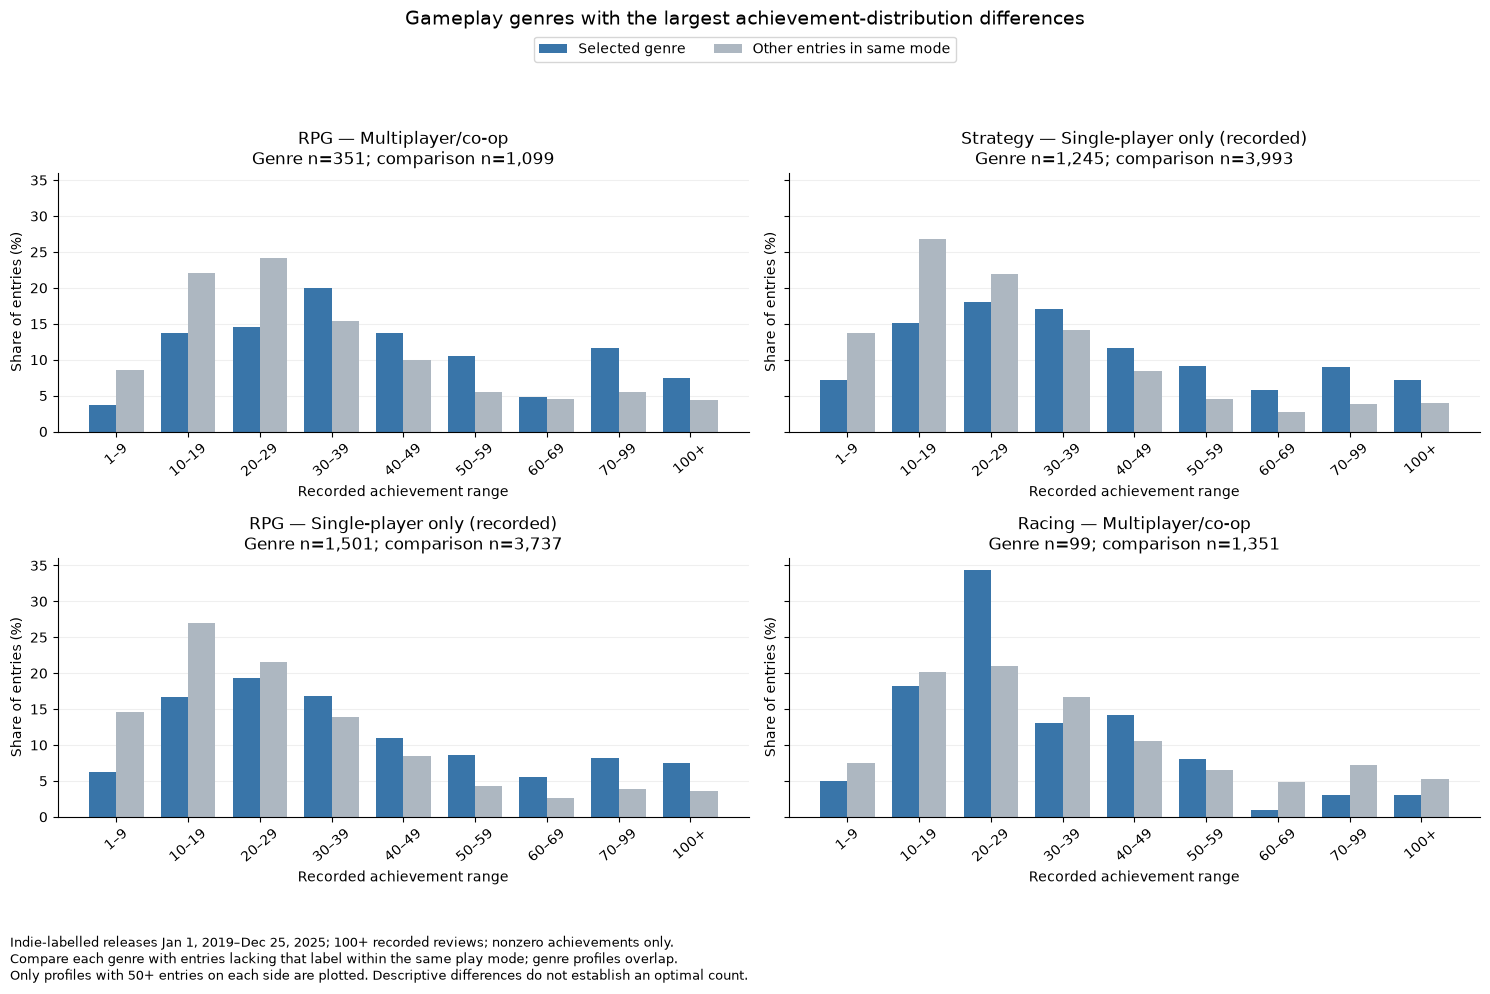

In [14]:
import matplotlib.pyplot as plt

genre_achievement_top = genre_achievement_summary.loc[
    genre_achievement_summary["enough_for_display"]
].head(4)
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
positions = np.arange(len(genre_achievement_labels))
width = 0.38

for ax, (_, profile) in zip(axes.flat, genre_achievement_top.iterrows()):
    distributions = genre_achievement_profiles[(profile["genre"], profile["play_mode"])]
    ax.bar(positions - width / 2, distributions["Genre (%)"], width,
           label="Selected genre", color="#3975a9")
    ax.bar(positions + width / 2, distributions["Other entries in same mode (%)"], width,
           label="Other entries in same mode", color="#adb7c1")
    mode_name = "Single-player only (recorded)" if profile["play_mode"] == achievement_mode_order[0] else "Multiplayer/co-op"
    ax.set_title(
        f"{profile['genre']} — {mode_name}\n"
        f"Genre n={profile['entries']:,}; comparison n={profile['comparison_entries']:,}"
    )
    ax.set_xticks(positions, genre_achievement_labels, rotation=40)
    ax.set_xlabel("Recorded achievement range")
    ax.set_ylabel("Share of entries (%)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for ax in list(axes.flat)[len(genre_achievement_top):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=2)
fig.suptitle("Gameplay genres with the largest achievement-distribution differences", fontsize=14)
fig.text(
    0.01, 0.01,
    "Indie-labelled releases Jan 1, 2019–Dec 25, 2025; 100+ recorded reviews; nonzero achievements only.\n"
    "Compare each genre with entries lacking that label within the same play mode; genre profiles overlap.\n"
    "Only profiles with 50+ entries on each side are plotted. Descriptive differences do not establish an optimal count.",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.09, 1, 0.91])
plt.show()

## 6. Pool play modes, compare RPG, Strategy, and Racing, then inspect reception tiers

Pool all eligible entries regardless of play mode, including unclassified modes because classification is unnecessary here. Keep the current Indie 2019–2025 and 100+ recorded review scope. Omit zero achievements only from distribution plots and the distribution-based genre ranking; preserve them in the reception-tier audit below.

Using the same eight gameplay genres and detailed achievement ranges. Rank each genre by the descriptive distribution gap versus entries without that genre label in the pooled sample. Require at least 50 nonzero-achievement entries on each side. Select the two highest-ranked genres and include Racing as requested; the distribution ranking remains visible. This selection is not a search for the most distant pair. Genre populations can overlap, so these are not independent genre samples.

For each selected genre, compare distributions conditional on reception: above 85%, 65–85% inclusive, and below 65%. Within each genre/tier, normalize over entries with nonzero achievements. Use common axes and show counts. These are exploratory comparisons selected from the same data, not evidence of an optimal count or a causal effect.

In [15]:
pooled_achievement_source = achievement_df.loc[
    achievement_df["Achievements"].gt(0)
].copy()
pooled_achievement_labels = single_achievement_labels[1:]
pooled_achievement_source["detailed_achievement_group"] = pd.cut(
    pooled_achievement_source["Achievements"],
    bins=[0, 9, 19, 29, 39, 49, 59, 69, 99, np.inf],
    labels=pooled_achievement_labels, right=True,
)
pooled_genre_sets = pooled_achievement_source["Genres"].str.split(",").apply(
    lambda labels: {label.strip() for label in labels}
)

pooled_genre_rows = []
pooled_genre_profiles = {}
for genre in gameplay_achievement_genres:
    member = pooled_genre_sets.apply(lambda labels: genre in labels)
    selected = pooled_achievement_source.loc[member]
    comparison = pooled_achievement_source.loc[~member]
    if selected.empty or comparison.empty:
        continue
    selected_pct = selected["detailed_achievement_group"].value_counts(
        sort=False
    ).reindex(pooled_achievement_labels, fill_value=0) / len(selected) * 100
    comparison_pct = comparison["detailed_achievement_group"].value_counts(
        sort=False
    ).reindex(pooled_achievement_labels, fill_value=0) / len(comparison) * 100
    pooled_genre_profiles[genre] = pd.DataFrame({
        "Genre (%)": selected_pct,
        "Other entries (%)": comparison_pct,
    })
    pooled_genre_rows.append({
        "genre": genre,
        "entries": len(selected),
        "comparison_entries": len(comparison),
        "median_achievements": selected["Achievements"].median(),
        "pct_50_plus": selected["Achievements"].ge(50).mean() * 100,
        "distribution_gap_pp": (selected_pct - comparison_pct).abs().sum() / 2,
        "enough_for_display": len(selected) >= 50 and len(comparison) >= 50,
    })

pooled_genre_ranking = pd.DataFrame(pooled_genre_rows).sort_values(
    ["distribution_gap_pp", "genre"], ascending=[False, True]
)
selected_achievement_genres = pooled_genre_ranking.loc[
    pooled_genre_ranking["enough_for_display"], "genre"
].head(2).tolist()
if "Racing" not in selected_achievement_genres:
    selected_achievement_genres.append("Racing")
print("Genres for reception-tier comparison (top two plus Racing):",
      ", ".join(selected_achievement_genres))
pooled_genre_ranking.round(1)

Genres for reception-tier comparison (top two plus Racing): RPG, Strategy, Racing


,genre,entries,comparison_entries,median_achievements,pct_50_plus,distribution_gap_pp,enough_for_display
3,RPG,1865,4884,35.0,30.9,21.0,True
5,Strategy,1629,5120,35.0,30.9,18.5,True
7,Racing,176,6573,28.0,17.0,12.3,True
2,Casual,2589,4160,24.0,20.4,9.9,True
0,Action,2895,3854,29.0,20.4,7.3,True
6,Sports,233,6516,24.0,16.7,7.2,True
4,Simulation,1964,4785,28.5,23.5,6.6,True
1,Adventure,3525,3224,26.0,18.0,4.0,True


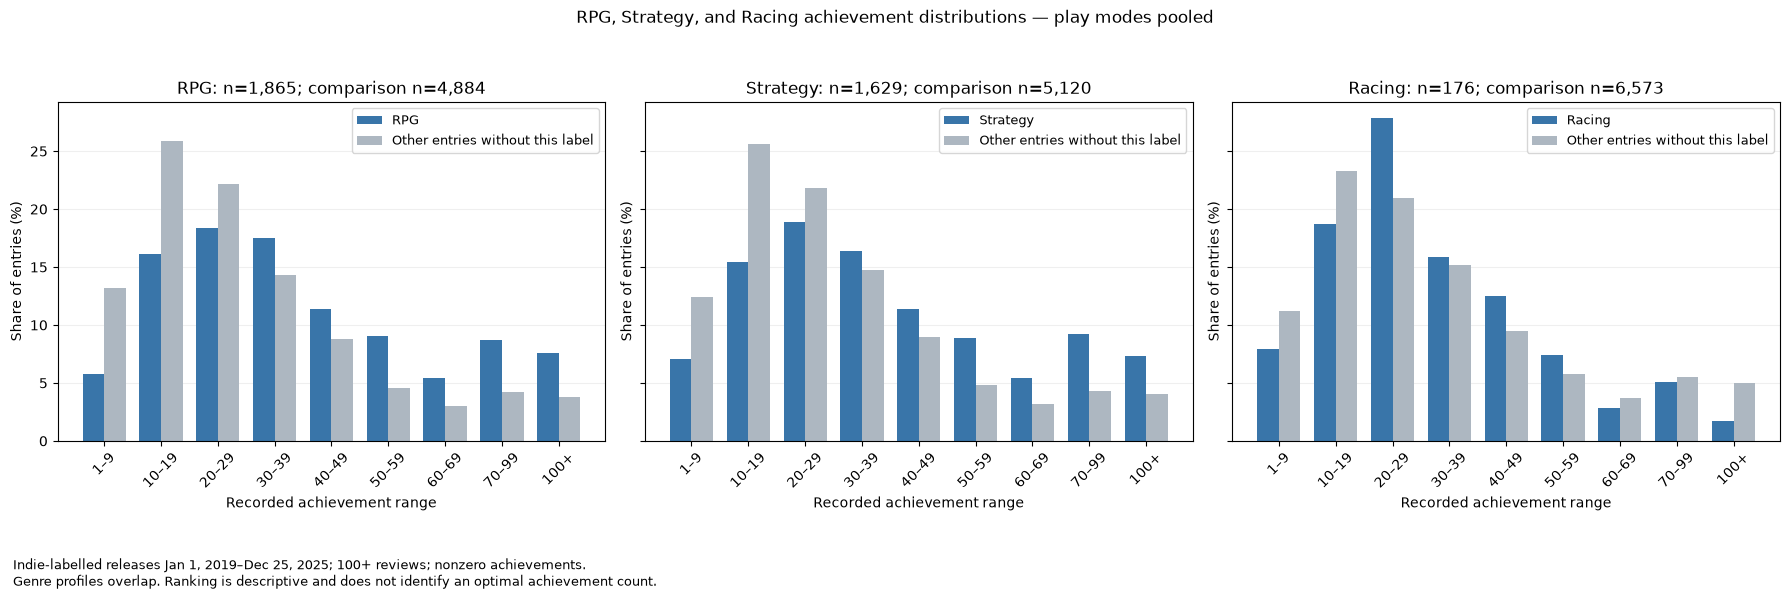

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(selected_achievement_genres), figsize=(18, 6), sharey=True)
positions = np.arange(len(pooled_achievement_labels))
width = 0.38
for ax, genre in zip(axes, selected_achievement_genres):
    profile = pooled_genre_profiles[genre]
    row = pooled_genre_ranking.loc[pooled_genre_ranking["genre"].eq(genre)].iloc[0]
    ax.bar(positions - width / 2, profile["Genre (%)"], width,
           label=genre, color="#3975a9")
    ax.bar(positions + width / 2, profile["Other entries (%)"], width,
           label="Other entries without this label", color="#adb7c1")
    ax.set_title(f"{genre}: n={row['entries']:,}; comparison n={row['comparison_entries']:,}")
    ax.set_xticks(positions, pooled_achievement_labels, rotation=45)
    ax.set_xlabel("Recorded achievement range")
    ax.set_ylabel("Share of entries (%)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=9)
fig.suptitle("RPG, Strategy, and Racing achievement distributions — play modes pooled")
fig.text(0.01, 0.02,
         "Indie-labelled releases Jan 1, 2019–Dec 25, 2025; 100+ reviews; nonzero achievements.\n"
         "Genre profiles overlap. Ranking is descriptive and does not identify an optimal achievement count.",
         fontsize=9)
plt.tight_layout(rect=[0, 0.12, 1, 0.94])
plt.show()

In [17]:
pooled_genre_review_source = achievement_df.copy()
pooled_genre_review_source["reception_tier"] = np.select(
    [
        pooled_genre_review_source["positive_share"].gt(0.85),
        pooled_genre_review_source["positive_share"].between(0.65, 0.85),
    ], reception_tier_order[:2], default=reception_tier_order[2],
)
pooled_genre_review_source["detailed_achievement_group"] = pd.cut(
    pooled_genre_review_source["Achievements"],
    bins=[0, 9, 19, 29, 39, 49, 59, 69, 99, np.inf],
    labels=pooled_achievement_labels, right=True,
)
pooled_review_genre_sets = pooled_genre_review_source["Genres"].str.split(",").apply(lambda labels: {label.strip() for label in labels})
selected_genre_tier_counts = {}
selected_genre_tier_pct = {}
selected_genre_audit_rows = []
for genre in selected_achievement_genres:
    member = pooled_review_genre_sets.apply(lambda labels: genre in labels)
    genre_entries = pooled_genre_review_source.loc[member]
    nonzero = genre_entries.loc[genre_entries["Achievements"].gt(0)]
    counts = pd.crosstab(
        nonzero["detailed_achievement_group"], nonzero["reception_tier"], dropna=False
    ).reindex(index=pooled_achievement_labels, columns=reception_tier_order, fill_value=0)
    selected_genre_tier_counts[genre] = counts
    selected_genre_tier_pct[genre] = counts.div(
        counts.sum(axis=0).replace(0, np.nan), axis=1
    ) * 100
    for tier in reception_tier_order:
        tier_entries = genre_entries.loc[genre_entries["reception_tier"].eq(tier)]
        selected_genre_audit_rows.append({
            "genre": genre, "reception_tier": tier,
            "all_entries": len(tier_entries),
            "zero_achievements_hidden": int(tier_entries["Achievements"].eq(0).sum()),
            "nonzero_entries_shown": int(counts[tier].sum()),
        })
selected_genre_tier_audit = pd.DataFrame(selected_genre_audit_rows).set_index(
    ["genre", "reception_tier"]
)
selected_genre_tier_audit

all_entries  zero_achievements_hidden  \
genre    reception_tier                                          
RPG      Above 85%              1111                       233   
         65–85%                 1008                       208   
         Below 65%               283                        96   
Strategy Above 85%               844                       133   
         65–85%                  895                       144   
         Below 65%               232                        65   
Racing   Above 85%               125                        26   
         65–85%                   98                        29   
         Below 65%                24                        16   

                         nonzero_entries_shown  
genre    reception_tier                         
RPG      Above 85%                         878  
         65–85%                            800  
         Below 65%                         187  
Strategy Above 85%                         711  
         65–85%                            751  
         Below 65%                         167  
Racing   Above 85%                          99  
         65–85%                             69  
         Below 65%                           8

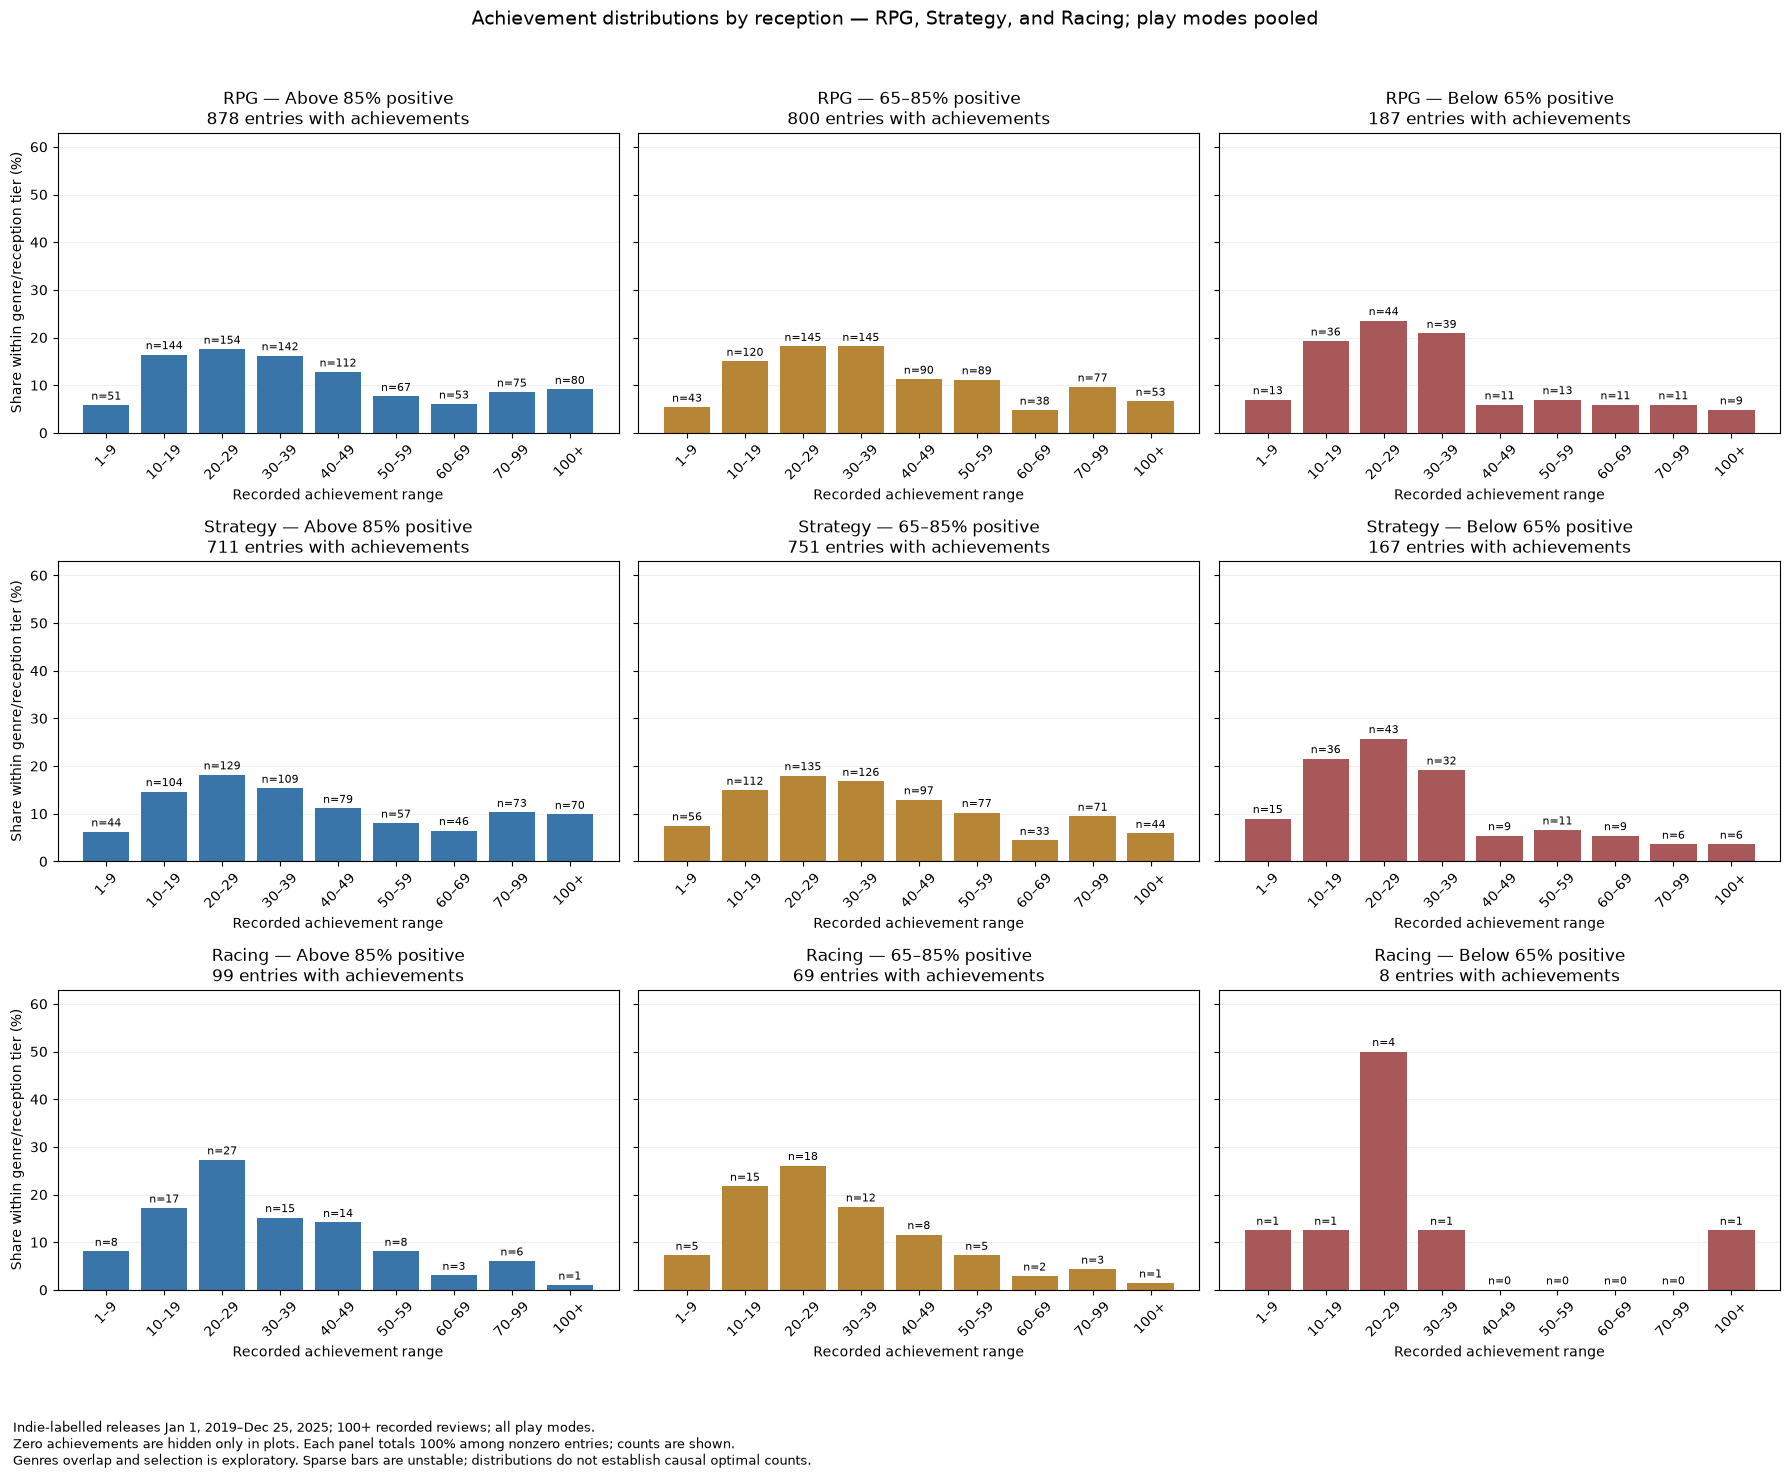

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(selected_achievement_genres), 3, figsize=(18, 15), sharey=True)
tier_colors = ["#3975a9", "#b78536", "#a85858"]
common_upper = min(100, max(
    percentages.max().max() for percentages in selected_genre_tier_pct.values()
) * 1.2 + 3)

for row, genre in enumerate(selected_achievement_genres):
    for col, (tier, color) in enumerate(zip(reception_tier_order, tier_colors)):
        ax = axes[row, col]
        counts = selected_genre_tier_counts[genre][tier]
        percentages = selected_genre_tier_pct[genre][tier]
        ax.bar(pooled_achievement_labels, percentages.to_numpy(), color=color)
        for position, (count, percentage) in enumerate(zip(counts, percentages)):
            if pd.notna(percentage):
                ax.text(position, percentage + 0.6, f"n={int(count):,}",
                        ha="center", va="bottom", fontsize=8)
        ax.set_title(f"{genre} — {tier} positive\n{int(counts.sum()):,} entries with achievements")
        ax.set_xlabel("Recorded achievement range")
        ax.tick_params(axis="x", rotation=45)
        ax.set_ylim(0, common_upper)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        if col == 0:
            ax.set_ylabel("Share within genre/reception tier (%)")

fig.suptitle("Achievement distributions by reception — RPG, Strategy, and Racing; play modes pooled", fontsize=14)
fig.text(0.01, 0.01,
         "Indie-labelled releases Jan 1, 2019–Dec 25, 2025; 100+ recorded reviews; all play modes.\n"
         "Zero achievements are hidden only in plots. Each panel totals 100% among nonzero entries; counts are shown.\n"
         "Genres overlap and selection is exploratory. Sparse bars are unstable; distributions do not establish causal optimal counts.",
         fontsize=9)
plt.tight_layout(rect=[0, 0.07, 1, 0.96])
plt.show()

## Conclusion

Among Indie-labelled games released in 2019–2025 with at least 100 recorded reviews, achievement counts provide useful design context but do not establish a universal optimum.

- 10–29 achievements is common across reception tiers, including poorly reviewed games. Its popularity alone does not make it the best range.
- Genre matters. RPG and Strategy games tend to offer more achievements; both have a median of 35 among entries with nonzero counts.
- Play-mode patterns differ. Multiplayer/co-op reception generally rises across the broader achievement groups, while single-player reception shows no consistent upward pattern.
- Genre-specific reception distributions overlap. Some differences warrant further investigation, but sparse groups—particularly Racing’s lowest-reception tier—cannot support firm recommendations.

Changing reception thresholds and achievement ranges did not establish a clear optimal count. These exploratory comparisons also do not isolate achievement count from genre, game size, price, release period, or development resources.

For an indie developer, the findings support using comparable games as a design reference—not targeting a specific achievement count as a formula for success. The dataset measures recorded counts, not achievement quality, player engagement with achievements, or commercial profitability.